In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os
import PIL
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequentialضض

In [2]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url,  cache_dir='.', untar=True)
# cache_dir indicates where to download data. I specified . which means current directory
# untar true will unzip it

In [3]:
import pathlib
data_dir = pathlib.Path(data_dir)
data_dir

WindowsPath('datasets/flower_photos')

In [4]:
list(data_dir.glob('*/*.jpg'))[::500]

[WindowsPath('datasets/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/5876455546_32049e5585.jpg'),
 WindowsPath('datasets/flower_photos/dandelion/2516714633_87f28f0314.jpg'),
 WindowsPath('datasets/flower_photos/dandelion/8981659922_7b1be892e7_m.jpg'),
 WindowsPath('datasets/flower_photos/roses/5402157745_a384f0583d_n.jpg'),
 WindowsPath('datasets/flower_photos/sunflowers/3749090865_b90f28a585_n.jpg'),
 WindowsPath('datasets/flower_photos/tulips/13999392173_b1411f8b23_n.jpg'),
 WindowsPath('datasets/flower_photos/tulips/6934951920_d43ff8b78d.jpg')]

In [5]:
image_count = len(list(data_dir.glob("*/*.jpg")))
image_count

3670

In [6]:
list(data_dir.glob("*"))

[WindowsPath('datasets/flower_photos/daisy'),
 WindowsPath('datasets/flower_photos/dandelion'),
 WindowsPath('datasets/flower_photos/LICENSE.txt'),
 WindowsPath('datasets/flower_photos/roses'),
 WindowsPath('datasets/flower_photos/sunflowers'),
 WindowsPath('datasets/flower_photos/tulips')]

In [9]:
daisy = list(data_dir.glob("daisy/*.jpg"))
dandelion = list(data_dir.glob("dandelion/*.jpg"))
roses = list(data_dir.glob("roses/*.jpg"))
sunflowers = list(data_dir.glob("sunflowers/*.jpg"))
tulips = list(data_dir.glob("tulips/*.jpg"))
len(daisy)+ len(dandelion) + len(roses) + len(sunflowers) + len(tulips)

3670

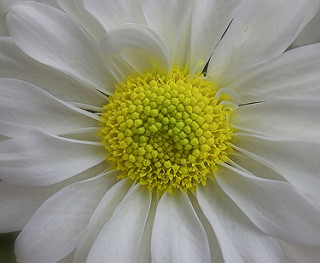

In [10]:
PIL.Image.open(daisy[0])

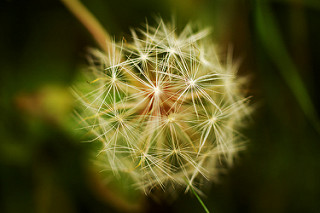

In [11]:
PIL.Image.open(dandelion[0])

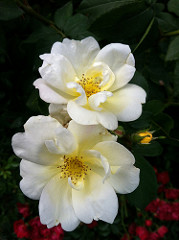

In [12]:
PIL.Image.open(roses[0])

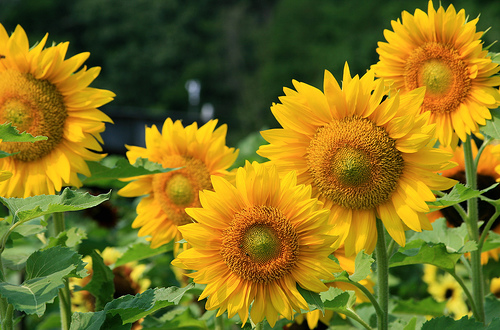

In [13]:
PIL.Image.open(sunflowers[0])

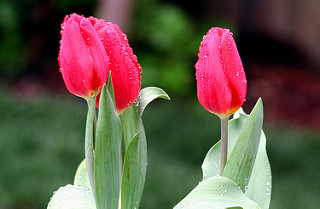

In [14]:
PIL.Image.open(tulips[0])

In [17]:
flowers_image_dic = {
    "daisy" : daisy ,
    "dandelion" : dandelion ,
    "roses" : roses ,
    "sunflowers" : sunflowers ,
    "tulips" : tulips ,
}
flowers_label_dic = {
    "daisy" : 0 ,
    "dandelion" : 1 ,
    "roses" : 2 ,
    "sunflowers" : 3 ,
    "tulips" : 5 ,
}

In [36]:
x, y = [], []

In [37]:
%%timeit -n1 -r1 
for flower_name , images in flowers_image_dic.items():
    for image in images:
        img = cv2.imread(str(image))
        resized_image = cv2.resize(img , (180,180))
        x.append(resized_image)
        y.append(flowers_label_dic[flower_name])

4.51 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [38]:
x = np.array(x)
y = np.array(y)

In [40]:
x.shape , y.shape

((3670, 180, 180, 3), (3670,))

In [43]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x , y , test_size=0.25 , random_state=5)

In [45]:
X_train.shape , X_test.shape, y_train.shape, y_test.shape

((2752, 180, 180, 3), (918, 180, 180, 3), (2752,), (918,))

In [47]:
X_train_scaled = X_train / 255.0
x_test_scaled = X_test / 255.0

In [51]:
X_train_scaled[0][0][0] , X_train[0][0][0]

(array([0.99215686, 0.96862745, 0.95294118]),
 array([253, 247, 243], dtype=uint8))

In [66]:
%%timeit -n1 -r1 
num_classes = len(flowers_label_dic)
num_classes

cnn_model_1 = Sequential([
   #cnn
    layers.Conv2D(16 , 4 , padding="same" , activation='relu'),
    layers.MaxPooling2D() , 
    layers.Conv2D(32 , 4 , padding="same" , activation='relu'),
    layers.MaxPooling2D() , 
    layers.Conv2D(64 , 4 , padding="same" , activation='relu'),
    layers.MaxPooling2D() , 

    # ann
    layers.Flatten() , 
    layers.Dense(128 , activation='relu') , 
    layers.Dense(num_classes ) , 
])

7.11 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [67]:
%%timeit -n1 -r1 
cnn_model_1.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

5 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [68]:
%%timeit -n1 -r1 
cnn_model_1.fit(X_train_scaled , y_train ,epochs=30)

Epoch 1/30
86/86 [==============================] - 3s 25ms/step - loss: 0.0482 - accuracy: 0.9869
Epoch 2/30
86/86 [==============================] - 2s 25ms/step - loss: 0.0332 - accuracy: 0.9909
Epoch 3/30
86/86 [==============================] - 2s 25ms/step - loss: 0.0423 - accuracy: 0.9862
Epoch 4/30
86/86 [==============================] - 2s 25ms/step - loss: 0.0245 - accuracy: 0.9927
Epoch 5/30
86/86 [==============================] - 2s 25ms/step - loss: 0.0124 - accuracy: 0.9975
Epoch 6/30
86/86 [==============================] - 2s 26ms/step - loss: 0.0059 - accuracy: 0.9993
Epoch 7/30
86/86 [==============================] - 2s 26ms/step - loss: 0.0018 - accuracy: 0.9996
Epoch 8/30
86/86 [==============================] - 2s 27ms/step - loss: 0.0042 - accuracy: 0.9993
Epoch 9/30
86/86 [==============================] - 2s 25ms/step - loss: 0.0027 - accuracy: 0.9993
Epoch 10/30
86/86 [==============================] - 2s 25ms/step - loss: 0.0028 - accuracy: 0.9993
Epoch 11/

In [70]:
cnn_model_1.evaluate(x_test_scaled , y_test)

 5/29 [====>.........................] - ETA: 0s - loss: 2.7218 - accuracy: 0.7125

C:\Users\Humam\anaconda3\envs\dfds\lib\site-packages\keras\backend.py:5582: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


29/29 [==============================] - 1s 15ms/step - loss: 2.8658 - accuracy: 0.6688


[2.865787982940674, 0.6688452959060669]